# Municipality Education Funding - Vilnius City

This notebook explores recorded school funding in Vilnius city in 2024.
It examines funding sources, average funding per school across school types,
and the ten highest-funded schools by total funding and funding per student.
Regular and special schools are included.

In [19]:
import duckdb
import pandas as pd

pd.options.display.float_format = "{:,.2f}".format

with duckdb.connect(
    "../data/local/lithuanian_education_warehouse.duckdb",
    read_only=True,
) as connection:
    funding = connection.sql("""
        SELECT *
        FROM finansavimas_mokykla_metai
    """).df()

year = 2024
municipality_code = 13  # Vilnius city

selected_funding = funding[
    (funding["metai"] == year) & (funding["savivaldybes_kodas"] == municipality_code)
].copy()

display(selected_funding.head())

,mokyklos_kodas,savivaldybes_kodas,mokykla,mokyklos_tipas,mokyklos_tipo_grupe,mokyklos_savivaldybe,mokyklos_priklausomybes_tipas,mokyklos_priklausomybes_tipo_grupe,ar_specialioji_mokykla,mokyklos_iregistravimo_data,mokyklos_isregistravimo_data,mokslo_metai,ataskaitinis_periodas,metai,finansavimo_saltinis,suma,mokiniu_skaicius
7237,190008065,13,Vilniaus Pavilnio pagrindinė mokykla,Pagrindinė mokykla,Pagrindinė mokykla,Vilniaus m.,Savivaldybės,Valstybinė,False,2001-10-12,NaT,2024-2025,2024-12-31,2024,Iš kitų finansavimo šaltinių,"9,513.23",233
7238,190008065,13,Vilniaus Pavilnio pagrindinė mokykla,Pagrindinė mokykla,Pagrindinė mokykla,Vilniaus m.,Savivaldybės,Valstybinė,False,2001-10-12,NaT,2024-2025,2024-12-31,2024,Iš valstybės biudžeto,"1,130,846.62",233
7239,190008065,13,Vilniaus Pavilnio pagrindinė mokykla,Pagrindinė mokykla,Pagrindinė mokykla,Vilniaus m.,Savivaldybės,Valstybinė,False,2001-10-12,NaT,2024-2025,2024-12-31,2024,Iš savivaldybių biudžetų,"563,965.94",233
7240,190008065,13,Vilniaus Pavilnio pagrindinė mokykla,Pagrindinė mokykla,Pagrindinė mokykla,Vilniaus m.,Savivaldybės,Valstybinė,False,2001-10-12,NaT,2024-2025,2024-12-31,2024,"Iš ES, užsienio valstybių ir tarptautinių orga...","7,369.25",233
7261,300033284,13,Vilniaus Juozo Tallat-Kelpšos konservatorija,Gimnazija,Gimnazija,Vilniaus m.,Valstybinė,Valstybinė,False,2004-06-14,NaT,2024-2025,2024-12-31,2024,Iš savivaldybių biudžetų,"21,250.00",147


In [20]:
records = selected_funding.dropna(
    subset=["savivaldybes_kodas", "mokyklos_kodas"]
).copy()

records["suma"] = records["suma"].astype("float64")

school_totals = records.groupby(
    ["savivaldybes_kodas", "mokyklos_kodas"],
    as_index=False,
).agg(
    total_funding=("suma", "sum"),
    students=("mokiniu_skaicius", "first"),
)

total_funding = school_totals["total_funding"].sum()
number_of_schools = len(school_totals)
total_students = school_totals["students"].sum()
missing_student_counts = school_totals["students"].isna().sum()

print(f"Municipality Funding Overview — {year}")
print(f"Total recorded funding: €{total_funding:,.0f}")
print(f"Schools represented: {number_of_schools:,}")
print(f"Students with recorded counts: {total_students:,.0f}")

if total_students > 0:
    funding_per_student = total_funding / total_students
    print(f"Funding per student: €{funding_per_student:,.2f}")
else:
    print("Funding per student: unavailable")

if missing_student_counts > 0:
    print(
        f"Student counts are missing for {missing_student_counts} schools. "
        "Funding per student may be overstated."
    )

Municipality Funding Overview — 2024
Total recorded funding: €383,551,630
Schools represented: 122
Students with recorded counts: 74,376
Funding per student: €5,156.93
Student counts are missing for 1 schools. Funding per student may be overstated.


### Municipality Funding Overview in Vilnius City, 2024

This block uses the 2024 records for Vilnius city from
`finansavimas_mokykla_metai`, including regular and special schools.

Funding is added across all sources for each school, while its student count
is included once. The school totals are then combined to show total funding,
the number of schools, and the number of students with recorded counts.

Funding per student is calculated by dividing total funding by total recorded
students. Schools with missing student counts still contribute to the funding
total, which can overstate this figure.

In [21]:
funding_by_source = (
    records.groupby(
        "finansavimo_saltinis",
        as_index=False,
        dropna=False,
    )["suma"]
    .sum()
    .sort_values("suma", ascending=False)
)

funding_source_names = {
    "Iš valstybės biudžeto": "State budget",
    "Iš savivaldybių biudžetų": "Municipal budgets",
    "Iš ES, užsienio valstybių ir tarptautinių organizacijų lėšų": "EU, foreign and international funds",
    "Iš kitų finansavimo šaltinių": "Other sources",
}

funding_by_source["source"] = (
    funding_by_source["finansavimo_saltinis"]
    .map(funding_source_names)
    .fillna(funding_by_source["finansavimo_saltinis"])
    .fillna("Unspecified source")
)

display(funding_by_source)

,finansavimo_saltinis,suma,source
3,Iš valstybės biudžeto,"270,258,947.06",State budget
2,Iš savivaldybių biudžetų,"100,657,628.67",Municipal budgets
1,Iš kitų finansavimo šaltinių,"6,389,590.89",Other sources
0,"Iš ES, užsienio valstybių ir tarptautinių orga...","6,245,462.97","EU, foreign and international funds"


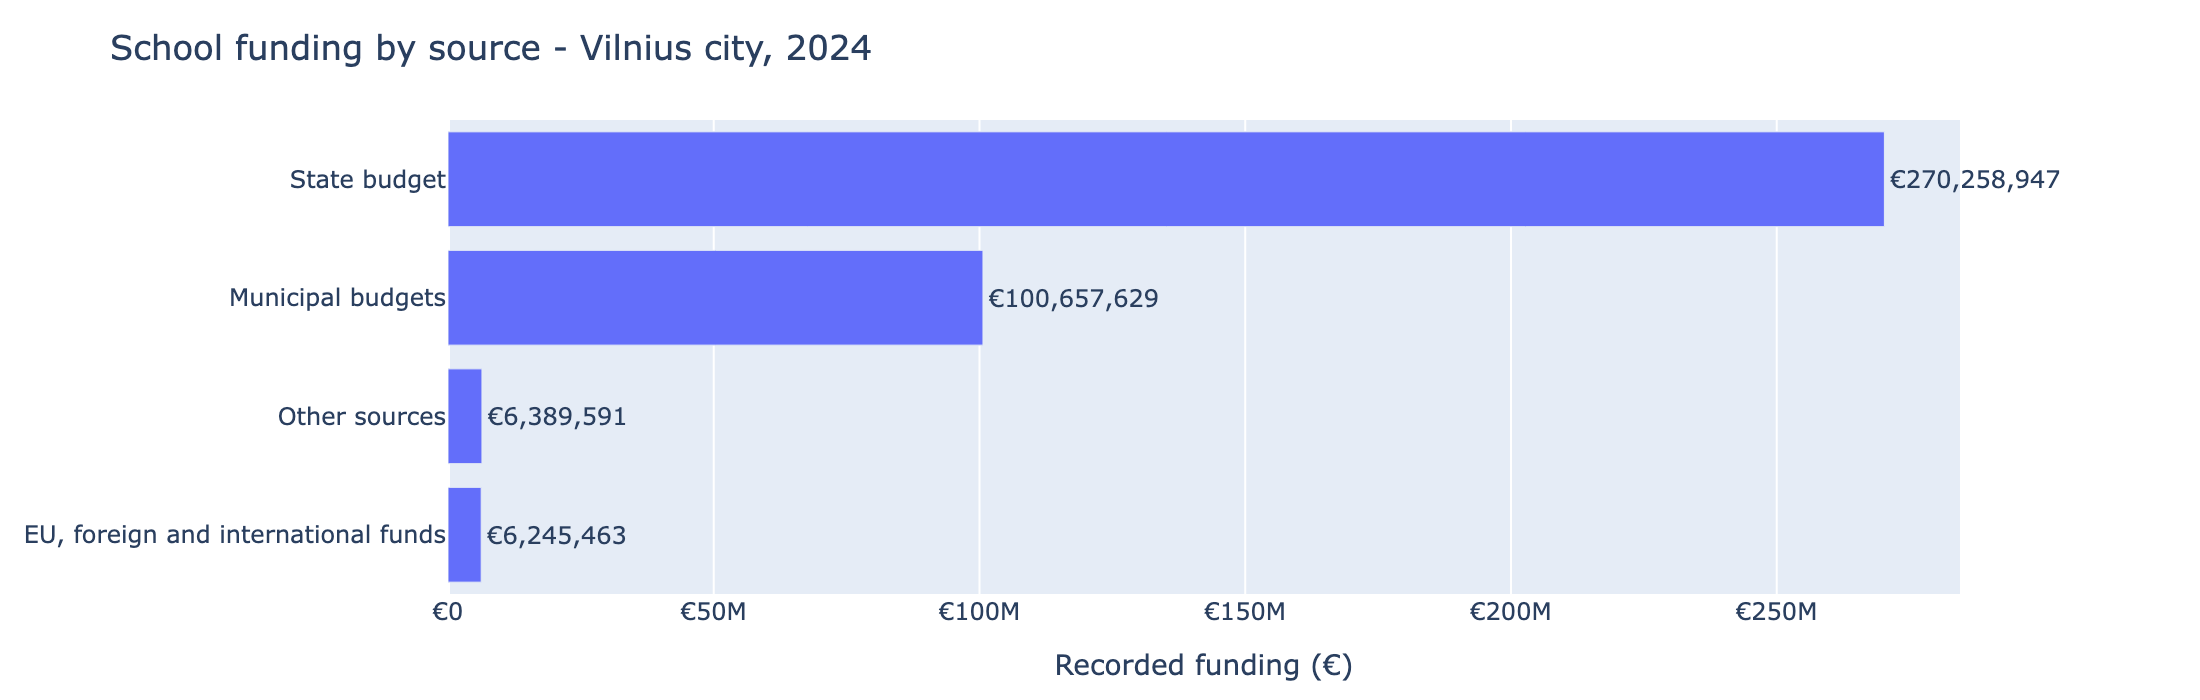

In [22]:
import plotly.express as px

figure = px.bar(
    funding_by_source,
    x="suma",
    y="source",
    orientation="h",
    text=[f"€{amount:,.0f}" for amount in funding_by_source["suma"]],
    labels={
        "suma": "Recorded funding (€)",
        "source": "Funding source",
    },
)

figure.update_traces(
    textposition="outside",
    cliponaxis=False,
)

figure.update_layout(
    title=f"School funding by source - Vilnius city, {year}",
    height=350,
    margin=dict(l=20, r=120, t=60, b=40),
)

figure.update_xaxes(
    tickprefix="€",
    tickformat="",
    exponentformat="B",
)

figure.update_yaxes(
    categoryorder="array",
    categoryarray=funding_by_source["source"].tolist(),
    autorange="reversed",
    title=None,
)

figure.show(config={"staticPlot": True, "displayModeBar": False})

### School Funding by Source - Vilnius City, 2024

This chart groups the selected municipality’s funding records by source and
adds the amounts within each group.

The horizontal bars show how much recorded funding came from each source,
ordered from largest to smallest. Labels show amounts rounded to whole euros.

The figures include regular and special schools represented in the dataset.

In [23]:
school_details = records.groupby("mokyklos_kodas")[
    ["mokykla", "mokyklos_tipas"]
].first()

schools = school_totals.join(
    school_details,
    on="mokyklos_kodas",
)

schools["mokyklos_tipas"] = (
    schools["mokyklos_tipas"].str.strip().replace("", pd.NA).fillna("Unspecified type")
)

funding_by_school_type = (
    schools.groupby("mokyklos_tipas", as_index=False)
    .agg(
        average_funding=("total_funding", "mean"),
        school_count=("mokyklos_kodas", "size"),
    )
    .sort_values("average_funding", ascending=False, kind="stable")
)

display(funding_by_school_type)

,mokyklos_tipas,average_funding,school_count
3,Progimnazija,"3,661,028.61",32
0,Gimnazija,"3,436,942.48",52
1,Pagrindinė mokykla,"2,975,705.10",15
2,Pradinė mokykla,"1,871,396.90",23


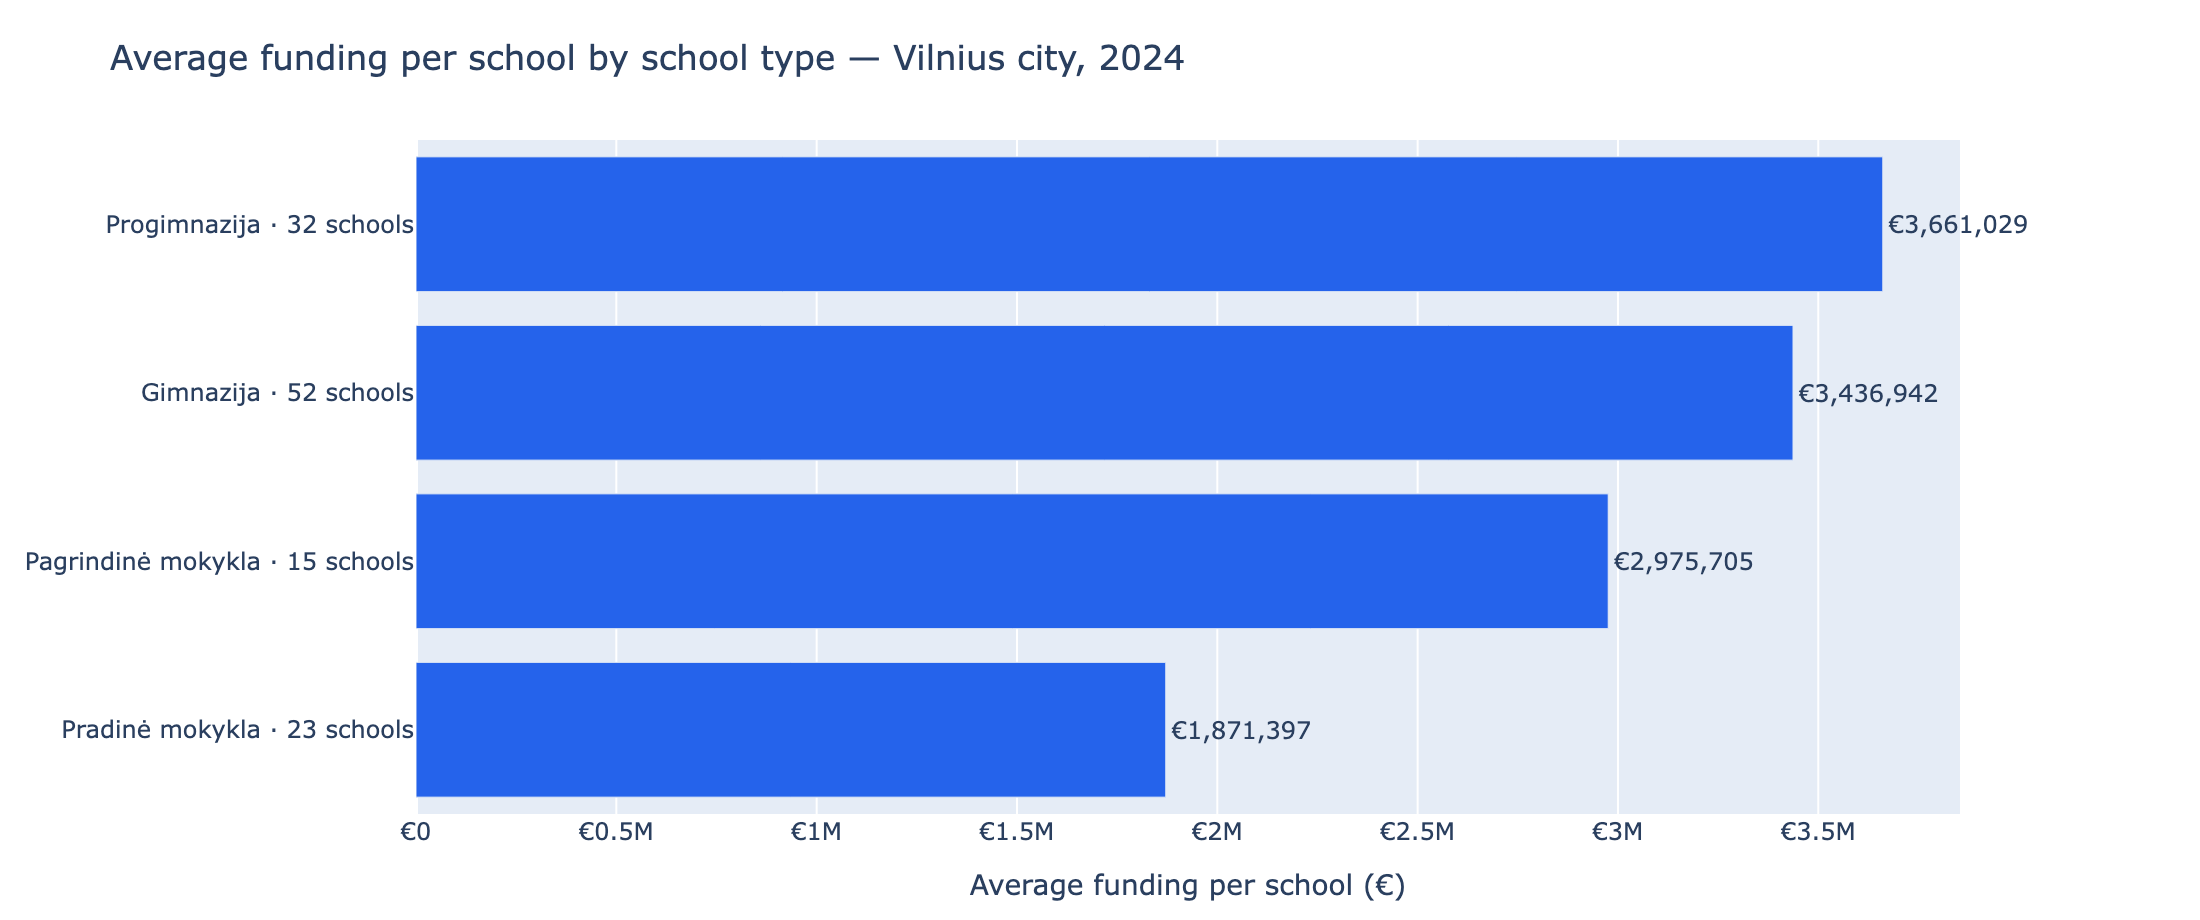

In [ ]:
school_counts = funding_by_school_type["school_count"].map(
    lambda count: f"{count:,} {'school' if count == 1 else 'schools'}"
)

funding_by_school_type["type_label"] = (
    funding_by_school_type["mokyklos_tipas"] + " · " + school_counts
)

figure = px.bar(
    funding_by_school_type,
    x="average_funding",
    y="type_label",
    orientation="h",
    text=[f"€{amount:,.0f}" for amount in funding_by_school_type["average_funding"]],
    labels={
        "average_funding": "Average funding per school (€)",
        "type_label": "School type",
    },
    color_discrete_sequence=["#2563eb"],
)

figure.update_traces(
    textposition="outside",
    cliponaxis=False,
)

figure.update_layout(
    title=f"Average funding per school by school type - Vilnius city, {year}",
    height=460,
    margin=dict(l=20, r=120, t=70, b=40),
)

figure.update_xaxes(
    tickprefix="€",
    tickformat="",
    exponentformat="B",
)

figure.update_yaxes(
    categoryorder="array",
    categoryarray=funding_by_school_type["type_label"].tolist(),
    autorange="reversed",
    automargin=True,
    title=None,
)

figure.show(config={"staticPlot": True, "displayModeBar": False})

### Average Funding per School by School Type - Vilnius City, 2024

This chart first adds each school's funding across all recorded sources.
It then groups schools by `mokyklos_tipas` and calculates the mean of their
annual funding totals.

Each horizontal bar shows the average funding received by one school of that
type. The category labels include the number of schools used in the calculation,
and bar labels show average amounts rounded to whole euros.

Regular and special schools represented in the selected records are included.


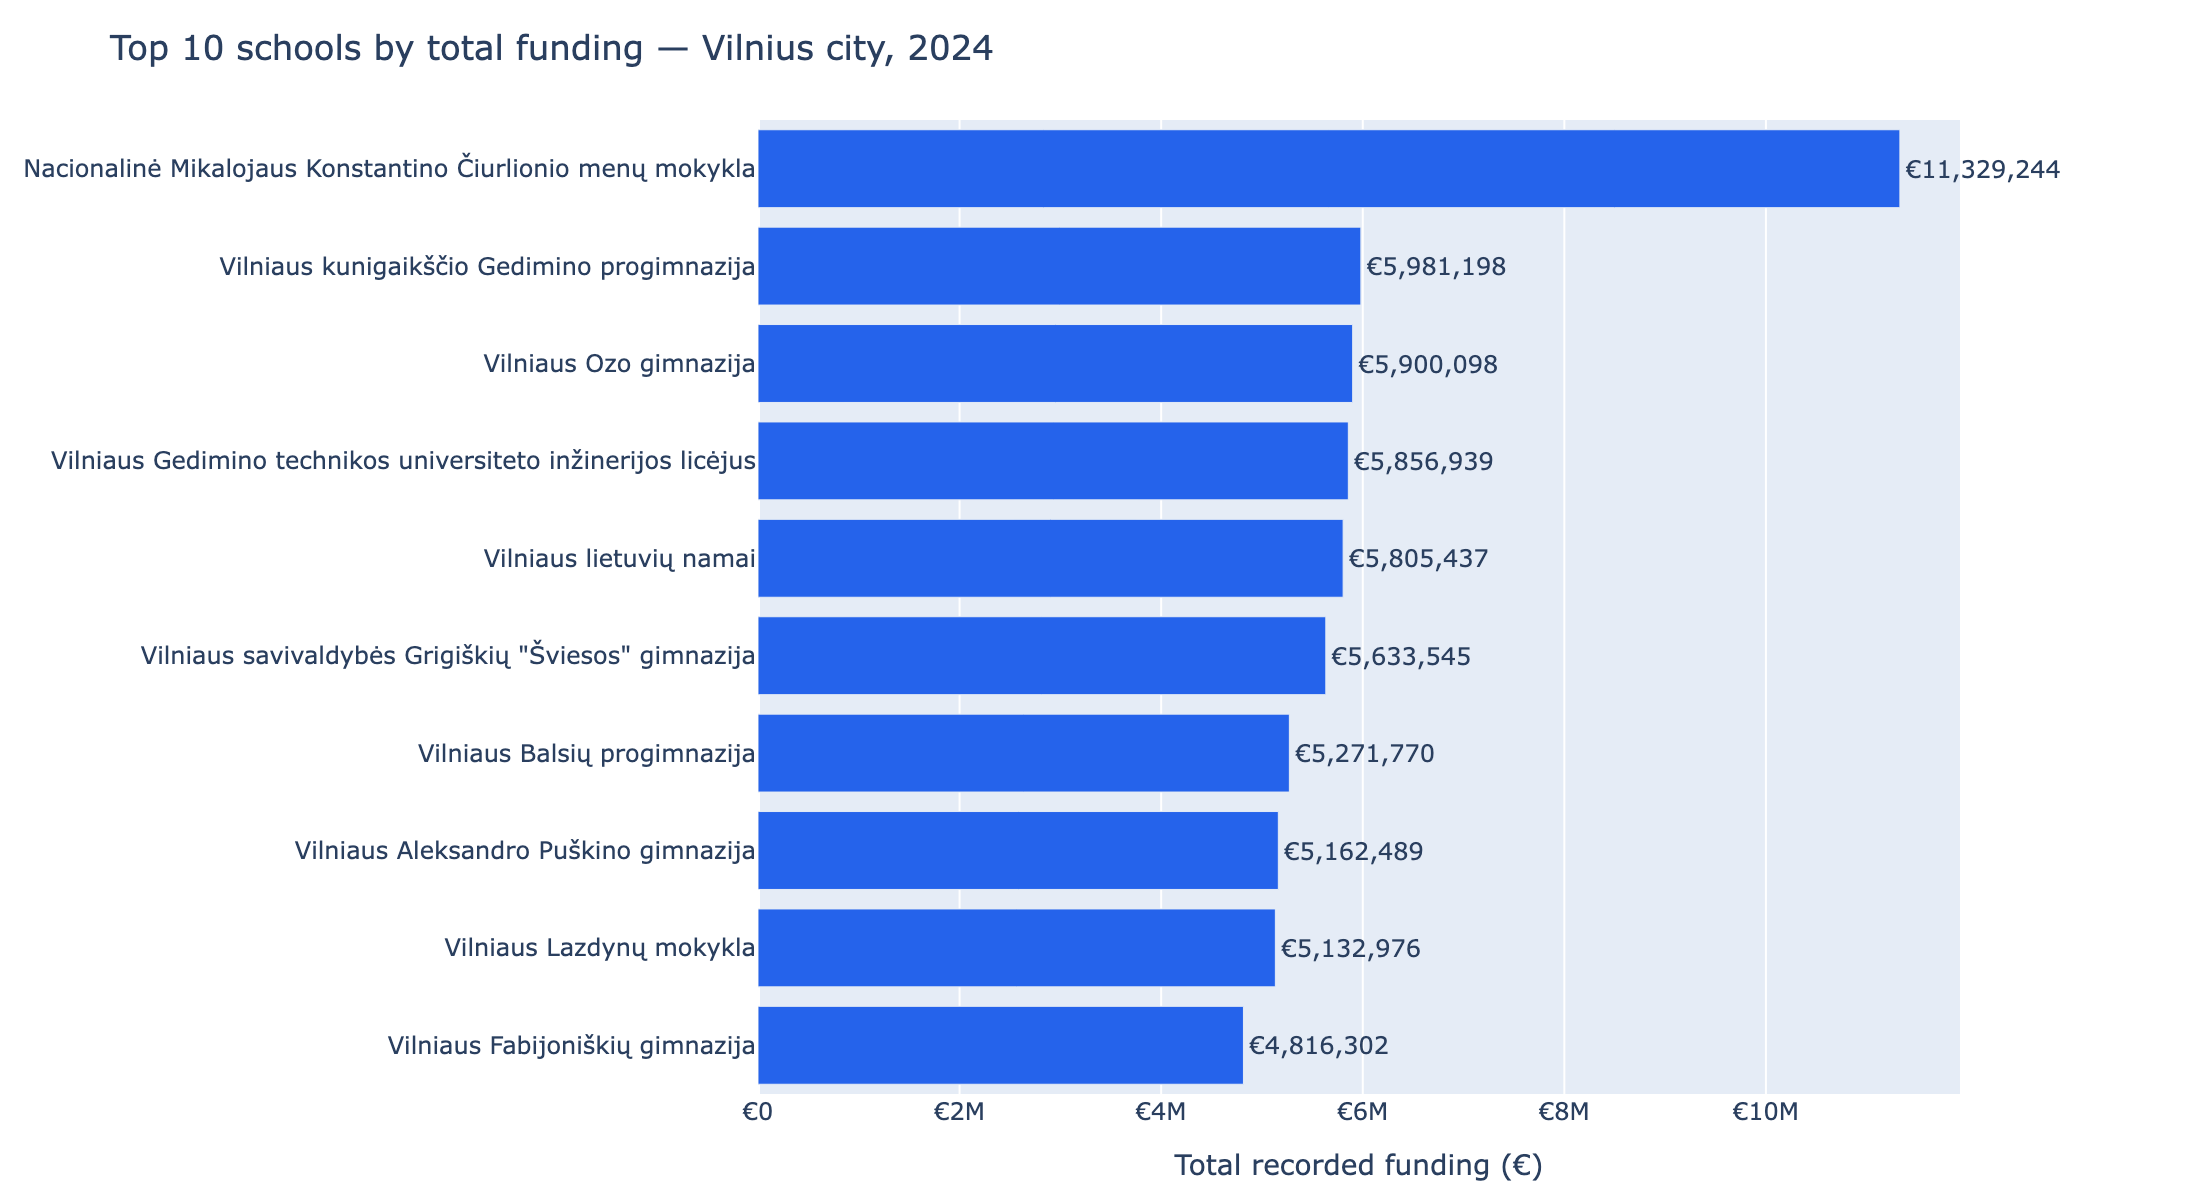

In [25]:
top_10_schools = schools.sort_values("total_funding", ascending=False).head(10)

figure = px.bar(
    top_10_schools,
    x="total_funding",
    y="mokykla",
    orientation="h",
    text=[f"€{amount:,.0f}" for amount in top_10_schools["total_funding"]],
    labels={
        "total_funding": "Total recorded funding (€)",
        "mokykla": "School",
    },
    color_discrete_sequence=["#2563eb"],
)

figure.update_traces(
    textposition="outside",
    cliponaxis=False,
)

figure.update_layout(
    title=f"Top 10 schools by total funding — Vilnius city, {year}",
    height=600,
    margin=dict(l=20, r=120, t=60, b=40),
)

figure.update_xaxes(
    tickprefix="€",
    tickformat="",
    exponentformat="B",
)

figure.update_yaxes(
    categoryorder="array",
    categoryarray=top_10_schools["mokykla"].tolist(),
    autorange="reversed",
    automargin=True,
    title=None,
)

figure.show(config={"staticPlot": True, "displayModeBar": False})

### Top 10 Schools by Total Funding - Vilnius City, 2024

This chart uses the school-level totals calculated from the selected municipality’s
funding records. It sorts schools by total recorded funding and displays the ten
highest totals.

All school types, including special schools, are eligible for the ranking.
The horizontal bars show each school’s funding across all recorded sources,
with amounts rounded to whole euros.

The ranking compares total funding without adjusting for the number of students.

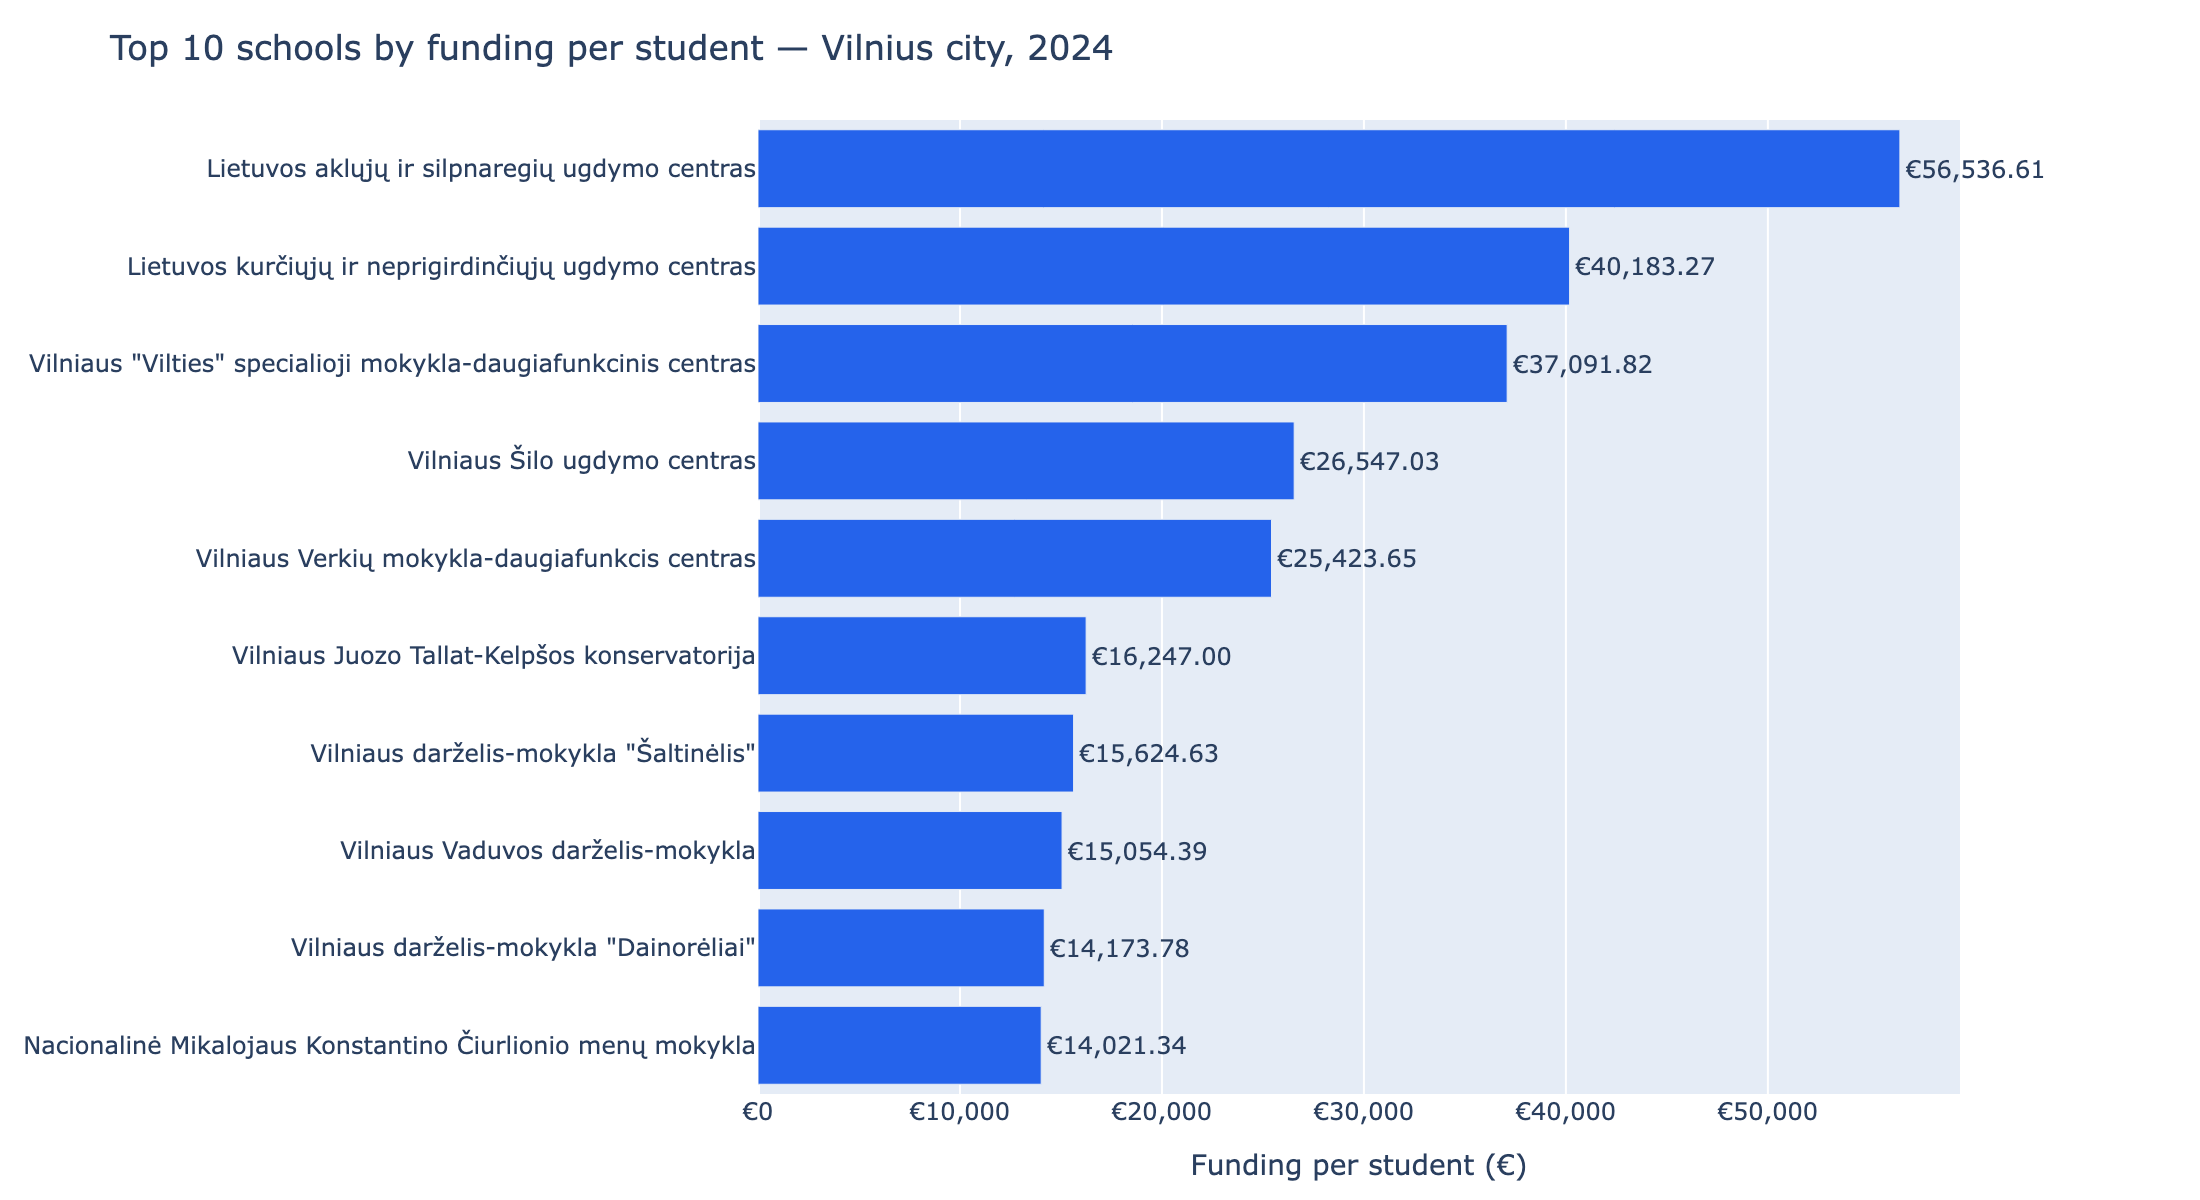

In [26]:
schools_per_student = schools[
    schools["students"].notna() & (schools["students"] > 0)
].copy()

schools_per_student["funding_per_student"] = (
    schools_per_student["total_funding"] / schools_per_student["students"]
)

top_10_per_student = schools_per_student.sort_values(
    "funding_per_student",
    ascending=False,
).head(10)

figure = px.bar(
    top_10_per_student,
    x="funding_per_student",
    y="mokykla",
    orientation="h",
    text=[f"€{amount:,.2f}" for amount in top_10_per_student["funding_per_student"]],
    labels={
        "funding_per_student": "Funding per student (€)",
        "mokykla": "School",
    },
    color_discrete_sequence=["#2563eb"],
)

figure.update_traces(
    textposition="outside",
    cliponaxis=False,
)

figure.update_layout(
    title=f"Top 10 schools by funding per student — Vilnius city, {year}",
    height=600,
    margin=dict(l=20, r=120, t=60, b=40),
)

figure.update_xaxes(
    tickprefix="€",
    tickformat=",.0f",
)

figure.update_yaxes(
    categoryorder="array",
    categoryarray=top_10_per_student["mokykla"].tolist(),
    autorange="reversed",
    automargin=True,
    title=None,
)

figure.show(config={"staticPlot": True, "displayModeBar": False})

### Top 10 Schools by Funding per Student - Vilnius City, 2024

This chart divides each school’s total recorded funding by its student count,
then displays the ten highest amounts.

All school types, including special schools, are eligible. Schools with missing
or zero student counts are excluded from this ranking.

The horizontal bars show funding per student, with amounts labelled to two
decimal places. Differences may reflect school size, type, and the services
provided.